# California and Wyoming Wind Power: A Six-Plant Comparison

This notebook compares the 24-hour wind power patterns of three selected plants in California (CA) and three in Wyoming (WY) in 2019. The goal is to see whether the two groups peak at different times and whether their combined capacity factor varies less.

**In Google Colab:** Choose **Runtime → Run all**. When the file picker appears, select the six original PLUSWIND CSVs together. Keep their original names; downloaded copies ending in `(1).csv` are also supported. In local Jupyter, put the files in `data/raw/` and run all cells.

Source: [PLUSWIND hourly modeled generation](https://wdh.energy.gov/ds/pluswind/plant.c0) ([DOI: 10.21947/1903602](https://doi.org/10.21947/1903602)). The figures use the ERA5 capacity factor with density and loss adjustments. These are modeled values.

## 1. Choose plants and years

| State | Plant | EIA plant ID |
|---|---|---:|
| CA | Solano Wind | 7526 |
| CA | Alta Wind Energy Center I | 57282 |
| CA | Dillon Wind | 56791 |
| WY | Glenrock | 56841 |
| WY | High Plains | 57040 |
| WY | Happy Jack Windpower Project | 56960 |

Start with 2019. To expand the analysis later, download one CSV per plant for each additional year and update `YEARS`.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("data/raw")
YEARS = [2019]
MODEL = "ERA5"  # Change to "HRRR" to compare a different model.
CF_COLUMN = f"{MODEL} CF (density and loss adjusted)"

PLANTS = {
    7526: ("CA", "Solano Wind"),
    57282: ("CA", "Alta Wind Energy Center I"),
    56791: ("CA", "Dillon Wind"),
    56841: ("WY", "Glenrock"),
    57040: ("WY", "High Plains"),
    56960: ("WY", "Happy Jack Windpower Project"),
}

## 2. Read and check the hourly files

The filename identifies the plant and year. The `gmt` column gives the hourly timestamp in UTC, so the two states can be compared at the same moment. Capacity factor is output divided by the plant's rated capacity. For example, 0.30 means 30%.

The code checks for missing files and repeated hours. It skips invalid timestamps and values outside the 0 to 1 range. Identical copies of an input file count only once.

In [2]:
pattern = re.compile(r"plant\.c0\.(\d{4})\.[^.]+\.(\d+)(?:\s*\(\d+\))?\.csv", re.I)
required = {(year, plant_id) for year in YEARS for plant_id in PLANTS}

def find_files():
    found = {}
    candidates = sorted(DATA_DIR.glob("*.csv")) + sorted(Path(".").glob("*.csv"))
    for path in candidates:
        match = pattern.fullmatch(path.name)
        if not match:
            continue
        key = tuple(map(int, match.groups()))
        if key not in required:
            continue
        if key in found and found[key].read_bytes() != path.read_bytes():
            raise ValueError(f"Different files found for year {key[0]}, plant {key[1]}. Keep only the intended CSV.")
        found.setdefault(key, path)
    return found

files_by_key = find_files()
if required - set(files_by_key):
    try:
        from google.colab import files
    except ImportError:
        pass
    else:
        print("Select the original PLUSWIND CSV files for all six plants.")
        files.upload()
        files_by_key = find_files()

missing = sorted(required - set(files_by_key))
if missing:
    needed = ", ".join(f"{year} / {plant}" for year, plant in missing)
    raise FileNotFoundError(f"Missing files (year / plant ID): {needed}. Upload them in Colab or place them in data/raw/.")

records, checks = [], []
for (year, plant_id), path in sorted(files_by_key.items()):
    raw = pd.read_csv(path, encoding="utf-8-sig")
    raw.columns = raw.columns.str.strip()
    if not {"gmt", CF_COLUMN}.issubset(raw.columns):
        raise ValueError(f"{path.name} needs the gmt and {CF_COLUMN} columns.")
    time = pd.to_datetime(raw["gmt"].astype("string"), format="%Y%m%d%H", utc=True, errors="coerce")
    cf = pd.to_numeric(raw[CF_COLUMN], errors="coerce")
    valid = time.dt.year.eq(year) & cf.between(0, 1)
    if time[valid].duplicated().any():
        raise ValueError(f"{path.name} has duplicate timestamps.")
    state, name = PLANTS[plant_id]
    records.append(pd.DataFrame({"time_utc": time[valid], "plant_id": plant_id,
                                 "state": state, "cf": cf[valid]}))
    expected = len(pd.date_range(f"{year}-01-01", f"{year+1}-01-01", inclusive="left", freq="h"))
    checks.append([year, state, plant_id, name, int(valid.sum()), expected - int(valid.sum())])

plant_hourly = pd.concat(records, ignore_index=True)
file_checks = pd.DataFrame(checks, columns=["Year", "State", "Plant ID", "Plant", "Valid hours", "Missing hours"])
print(file_checks.to_string(index=False))

 Year State  Plant ID                        Plant  Valid hours  Missing hours
 2019    CA      7526                  Solano Wind         8760              0
 2019    CA     56791                  Dillon Wind         8760              0
 2019    WY     56841                     Glenrock         8760              0
 2019    WY     56960 Happy Jack Windpower Project         8760              0
 2019    WY     57040                  High Plains         8760              0
 2019    CA     57282    Alta Wind Energy Center I         8760              0


## 3. Match all six plants by hour

Keep hours with valid values for all six plants. This keeps the same group of plants in each comparison. For this first comparison, give each plant equal weight. The combined series is the average of the two three-plant groups. It is an average capacity factor, not the total electricity produced in MW.

In [3]:
wide = (plant_hourly.pivot(index="time_utc", columns="plant_id", values="cf")
        .reindex(columns=list(PLANTS)).sort_index().dropna())
if wide.empty:
    raise ValueError("No hours overlap across all six plants. Check the input files.")

hourly = pd.DataFrame({
    state: wide[[pid for pid, (s, _) in PLANTS.items() if s == state]].mean(axis=1)
    for state in ("CA", "WY")
})
hourly["Combined"] = hourly[["CA", "WY"]].mean(axis=1)
print(f"Hours matched across all six plants: {len(hourly):,}")

Hours matched across all six plants: 8,760


## 4. Compare the 24-hour patterns by season

The horizontal axis uses the same UTC clock for both states. Each point is the average capacity factor at that hour of the day for the months shown. The combined line helps show how the daily pattern changes when the two groups are averaged.

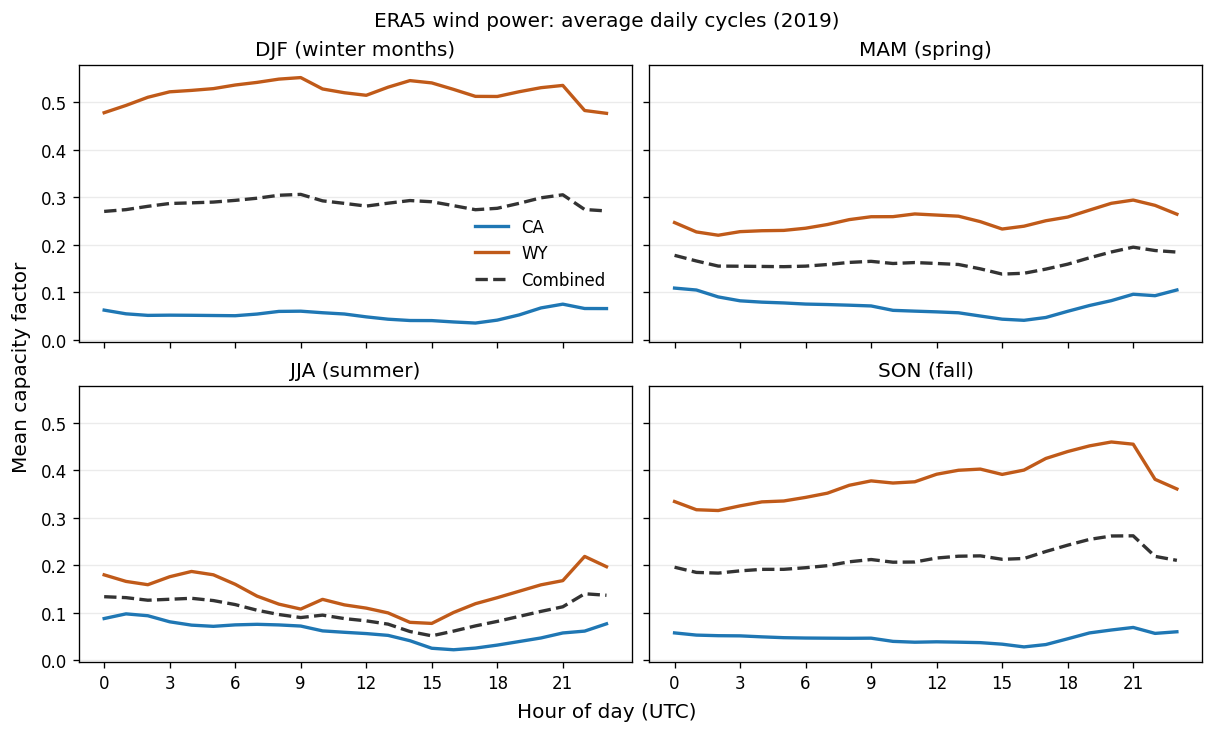

In [4]:
seasons = {"DJF (winter months)": [12, 1, 2], "MAM (spring)": [3, 4, 5],
           "JJA (summer)": [6, 7, 8], "SON (fall)": [9, 10, 11]}
colors = {"CA": "#1f77b4", "WY": "#c05a19", "Combined": "#333333"}
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True, layout="constrained")
for ax, (season, months) in zip(axes.flat, seasons.items()):
    season_data = hourly.loc[hourly.index.month.isin(months)]
    cycle = season_data.groupby(season_data.index.hour).mean().reindex(range(24))
    for series, color in colors.items():
        ax.plot(cycle.index, cycle[series], label=series, color=color,
                linestyle="--" if series == "Combined" else "-", linewidth=2)
    ax.set(title=season, xticks=range(0, 24, 3))
    ax.grid(axis="y", alpha=0.25)
axes[0, 0].legend(loc="center right", bbox_to_anchor=(0.98, 0.32), frameon=False)
fig.suptitle(f"{MODEL} wind power: average daily cycles ({', '.join(map(str, YEARS))})")
fig.supxlabel("Hour of day (UTC)")
fig.supylabel("Mean capacity factor")
plt.show()

## 5. Check the hourly relationship and variability

Correlation summarizes whether the two groups tend to rise and fall together at the same hours. Standard deviation measures how much hourly capacity factor varies. A smaller standard deviation for the combined series indicates smoother output in this equal-weight comparison. Peak timing and same-hour correlation describe different aspects of the data, so look at both.

In [5]:
def summarize(group):
    return {
        "Hours": len(group),
        "CA–WY correlation": group["CA"].corr(group["WY"]) if len(group) > 1 else np.nan,
        "CA SD": group["CA"].std(),
        "WY SD": group["WY"].std(),
        "Combined SD": group["Combined"].std(),
    }

summary = {"All hours": summarize(hourly)}
for season, months in seasons.items():
    summary[season] = summarize(hourly.loc[hourly.index.month.isin(months)])
metrics = pd.DataFrame.from_dict(summary, orient="index")
metrics["Hours"] = metrics["Hours"].astype(int)
print(metrics.to_string(float_format=lambda x: f"{x:.3f}"))

                     Hours  CA–WY correlation  CA SD  WY SD  Combined SD
All hours             8760             -0.103  0.065  0.300        0.150
DJF (winter months)   2160             -0.148  0.069  0.333        0.165
MAM (spring)          2208             -0.036  0.074  0.244        0.126
JJA (summer)          2208              0.162  0.047  0.150        0.082
SON (fall)            2184             -0.103  0.063  0.299        0.149


## Next steps

Repeat the comparison for 2018–2021 and with HRRR. Compare models using hours with valid data in both. For a combined series that reflects actual plant sizes, use rated capacities for the study years as weights. The results describe these six selected plants. See [PROJECT_CHECKLIST.md](PROJECT_CHECKLIST.md) for the remaining project work.